# Chapter 4 — Assignments 
Based on Chapter 4 Parts I and II.

**Instructions:** Complete all three assignments individually. 
Each assignment is worth **30 marks** (60 total); presentation, interpretation, and code quality are worth **10 marks**. Run all cells, explain your results in Markdown, and submit the completed `.ipynb`. Use NumPy array operations instead of explicit Python loops wherever practical. You may use Matplotlib for figures. Do not overwrite the original input arrays unless asked. Use a reproducible random seed. 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

---
# Assignment 1 — Student Performance Data Analysis (30 marks)
**Scenario:** A lecturer has exam results for 12 students in four modules. Investigate performance and identify students who need support. Complete **all six parts**.

**Starter data:** Rows represent students; columns represent Python, Mathematics, Electronics, and Networks. The scores are illustrative, not real student records.

In [ ]:
student_ids = np.array([f"ST{i:02d}" for i in range(1, 13)])
subjects = np.array(["Python", "Mathematics", "Electronics", "Networks"])
scores = np.array(
    [
    [76, 82, 69, 88], [55, 61, 58, 64], [91, 87, 93, 90],
    [44, 59, 62, 51], [72, 77, 74, 79], [88, 92, 85, 83],
    [63, 68, 71, 65], [95, 90, 89, 94], [58, 47, 54, 60],
    [81, 79, 84, 86], [69, 73, 66, 70], [49, 52, 46, 55]
    ], dtype=np.float64)

### Part A — Array structure and data types (5 marks)
1. Display `ndim`, `shape`, `size`, and `dtype` for `scores`.
2. Create an integer copy using `astype()` and explain the difference from the original.
3. Create a 12×4 Boolean array indicating whether each score is at least 50.
4. Explain why a two-dimensional ndarray is suitable for these data.

In [ ]:
# Part A — Array structure and data types
print("Dimensions:", scores.ndim)
print("Shape (students, subjects):", scores.shape)
print("Number of scores:", scores.size)
print("Original data type:", scores.dtype)

# astype() creates a separate integer array; decimal parts would be truncated.
scores_int = scores.astype(int)
print("\nInteger copy data type:", scores_int.dtype)
print("Original array data type is still:", scores.dtype)

# True means the score is at least 50; False means it is below 50.
score_at_least_50 = scores >= 50
print("\nBoolean array (score >= 50):")
print(score_at_least_50)

# Explanation:
# A 2D ndarray is suitable because rows represent students and columns represent subjects.
# It allows efficient slicing and calculations across rows or columns.

Dimensions: 2
Shape (students, subjects): (12, 4)
Number of scores: 48
Original data type: float64

Integer copy data type: int64
Original array data type is still: float64

Boolean array (score >= 50):
[[ True  True  True  True]
 [ True  True  True  True]
 [ True  True  True  True]
 [False  True  True  True]
 [ True  True  True  True]
 [ True  True  True  True]
 [ True  True  True  True]
 [ True  True  True  True]
 [ True False  True  True]
 [ True  True  True  True]
 [ True  True  True  True]
 [False  True False  True]]


### Part B — Indexing, slicing, and fancy indexing (5 marks)
1. Extract all scores for the first three students.
2. Extract only the Python and Networks columns for every student.
3. Select students at row indices `[1, 4, 7, 10]` using fancy indexing.
4. Use a transpose to show results as subjects × students. Report the resulting shape.

In [ ]:
# Part B — Indexing, slicing, and fancy indexing
first_three_students = scores[:3, :]
print("Scores for the first three students:")
print(first_three_students)

python_and_networks = scores[:, [0, 3]]
print("\nPython and Networks scores for every student:")
print(python_and_networks)

selected_rows = scores[[1, 4, 7, 10], :]
print("\nStudents at row indices [1, 4, 7, 10] (IDs ST02, ST05, ST08, ST11):")
print(selected_rows)

scores_transposed = scores.T
print("\nTransposed array (subjects × students):")
print(scores_transposed)
print("Transposed shape:", scores_transposed.shape)

# axis 0 originally represents students; axis 1 originally represents subjects.
# Transposing changes the shape from (12, 4) to (4, 12).

Scores for the first three students:
[[76. 82. 69. 88.]
 [55. 61. 58. 64.]
 [91. 87. 93. 90.]]

Python and Networks scores for every student:
[[76. 88.]
 [55. 64.]
 [91. 90.]
 [44. 51.]
 [72. 79.]
 [88. 83.]
 [63. 65.]
 [95. 94.]
 [58. 60.]
 [81. 86.]
 [69. 70.]
 [49. 55.]]

Students at row indices [1, 4, 7, 10] (IDs ST02, ST05, ST08, ST11):
[[55. 61. 58. 64.]
 [72. 77. 74. 79.]
 [95. 90. 89. 94.]
 [69. 73. 66. 70.]]

Transposed array (subjects × students):
[[76. 55. 91. 44. 72. 88. 63. 95. 58. 81. 69. 49.]
 [82. 61. 87. 59. 77. 92. 68. 90. 47. 79. 73. 52.]
 [69. 58. 93. 62. 74. 85. 71. 89. 54. 84. 66. 46.]
 [88. 64. 90. 51. 79. 83. 65. 94. 60. 86. 70. 55.]]
Transposed shape: (4, 12)


### Part C — Vectorized statistics (6 marks)
1. Calculate each student's mean and total using `axis`.
2. Calculate the mean, minimum, maximum, and standard deviation for each subject.
3. Find the highest-performing student by mean score (`argmax`) and report the student ID.
4. Calculate each student's score range (maximum minus minimum).
5. Explain the difference between `axis=0` and `axis=1` in this dataset.

In [ ]:
# Part C — Vectorized statistics
student_mean = np.mean(scores, axis=1)
student_total = np.sum(scores, axis=1)
print("Mean score for each student:")
for sid, mean in zip(student_ids, student_mean):
    print(f"{sid}: {mean:.2f}")
print("\nTotal score for each student:")
print(student_total)

subject_mean = np.mean(scores, axis=0)
subject_min = np.min(scores, axis=0)
subject_max = np.max(scores, axis=0)
subject_std = np.std(scores, axis=0)  # population standard deviation (ddof=0)
print("\nStatistics by subject:")
for i, subject in enumerate(subjects):
    print(f"{subject}: mean={subject_mean[i]:.2f}, min={subject_min[i]:.0f}, "
          f"max={subject_max[i]:.0f}, std={subject_std[i]:.2f}")

best_index = np.argmax(student_mean)
print(f"\nHighest-performing student by mean: {student_ids[best_index]} "
      f"({student_mean[best_index]:.2f})")

student_range = np.max(scores, axis=1) - np.min(scores, axis=1)
print("\nScore range (maximum - minimum) for each student:")
print(student_range)

# axis=0 reduces down the rows and gives one result per subject (column).
# axis=1 reduces across the columns and gives one result per student (row).

Mean score for each student:
ST01: 78.75
ST02: 59.50
ST03: 90.25
ST04: 54.00
ST05: 75.50
ST06: 87.00
ST07: 66.75
ST08: 92.00
ST09: 54.75
ST10: 82.50
ST11: 69.50
ST12: 50.50

Total score for each student:
[315. 238. 361. 216. 302. 348. 267. 368. 219. 330. 278. 202.]

Statistics by subject:
Python: mean=70.08, min=44, max=95, std=16.04
Mathematics: mean=72.25, min=47, max=92, std=14.30
Electronics: mean=70.92, min=46, max=93, std=14.07
Networks: mean=73.75, min=51, max=94, std=14.10

Highest-performing student by mean: ST08 (92.00)

Score range (maximum - minimum) for each student:
[19.  9.  6. 18.  7.  9.  8.  6. 13.  7.  7.  9.]


### Part D — Boolean filtering and conditional classification (5 marks)
1. Identify students with at least one score below 50, using a Boolean mask and `any()`.
2. Identify students with all four scores at least 70, using `all()`.
3. Classify each student's average using `np.where()` into **Pass** (mean ≥ 50) or **Fail**.
4. Count how many students pass and fail; explain whether average-based passing differs from passing every module.

In [ ]:
# Part D — Boolean filtering and conditional classification
has_score_below_50 = np.any(scores < 50, axis=1)
students_with_low_score = student_ids[has_score_below_50]
print("Students with at least one score below 50:", students_with_low_score)

all_scores_at_least_70 = np.all(scores >= 70, axis=1)
print("Students with all four scores at least 70:", student_ids[all_scores_at_least_70])

student_status = np.where(student_mean >= 50, "Pass", "Fail")
print("\nAverage-based classification:")
for sid, mean, status in zip(student_ids, student_mean, student_status):
    print(f"{sid}: mean={mean:.2f} -> {status}")

pass_count = np.count_nonzero(student_status == "Pass")
fail_count = np.count_nonzero(student_status == "Fail")
print(f"\nPass count: {pass_count}")
print(f"Fail count: {fail_count}")

# Average-based passing does not guarantee passing every module.
# A student may have an average >= 50 but still have one or more subject scores below 50.

Students with at least one score below 50: ['ST04' 'ST09' 'ST12']
Students with all four scores at least 70: ['ST03' 'ST05' 'ST06' 'ST08' 'ST10']

Average-based classification:
ST01: mean=78.75 -> Pass
ST02: mean=59.50 -> Pass
ST03: mean=90.25 -> Pass
ST04: mean=54.00 -> Pass
ST05: mean=75.50 -> Pass
ST06: mean=87.00 -> Pass
ST07: mean=66.75 -> Pass
ST08: mean=92.00 -> Pass
ST09: mean=54.75 -> Pass
ST10: mean=82.50 -> Pass
ST11: mean=69.50 -> Pass
ST12: mean=50.50 -> Pass

Pass count: 12
Fail count: 0


### Part E — Sorting and set operations (5 marks)
1. Rank students from highest to lowest average using `argsort()`.
2. Find the top three students and their means.
3. Find the student IDs who scored at least 80 in Python and those who scored at least 80 in Networks.
4. Use `np.intersect1d()` and `np.union1d()` to compare these groups. Explain the results.

In [ ]:
# Part E — Sorting and set operations
rank_order = np.argsort(student_mean)[::-1]
print("Students ranked from highest to lowest average:")
for rank, idx in enumerate(rank_order, start=1):
    print(f"{rank}. {student_ids[idx]} — {student_mean[idx]:.2f}")

top_three_indices = rank_order[:3]
print("\nTop three students:")
for idx in top_three_indices:
    print(f"{student_ids[idx]}: {student_mean[idx]:.2f}")

python_80_ids = student_ids[scores[:, 0] >= 80]
networks_80_ids = student_ids[scores[:, 3] >= 80]
both_subjects_80 = np.intersect1d(python_80_ids, networks_80_ids)
either_subject_80 = np.union1d(python_80_ids, networks_80_ids)

print("\nPython score >= 80:", python_80_ids)
print("Networks score >= 80:", networks_80_ids)
print("At least 80 in BOTH Python and Networks:", both_subjects_80)
print("At least 80 in EITHER Python or Networks:", either_subject_80)

# intersect1d returns IDs appearing in both groups; union1d returns unique IDs in either group.

Students ranked from highest to lowest average:
1. ST08 — 92.00
2. ST03 — 90.25
3. ST06 — 87.00
4. ST10 — 82.50
5. ST01 — 78.75
6. ST05 — 75.50
7. ST11 — 69.50
8. ST07 — 66.75
9. ST02 — 59.50
10. ST09 — 54.75
11. ST04 — 54.00
12. ST12 — 50.50

Top three students:
ST08: 92.00
ST03: 90.25
ST06: 87.00

Python score >= 80: ['ST03' 'ST06' 'ST08' 'ST10']
Networks score >= 80: ['ST01' 'ST03' 'ST06' 'ST08' 'ST10']
At least 80 in BOTH Python and Networks: ['ST03' 'ST06' 'ST08' 'ST10']
At least 80 in EITHER Python or Networks: ['ST01' 'ST03' 'ST06' 'ST08' 'ST10']


### Part F — File I/O and interpretation (4 marks)
1. Save the original scores to `assignment1_scores.npy` and load them back.
2. Verify that the reloaded array equals the original.
3. Plot the average score for each subject with a bar chart.
4. Write a 4–6 sentence interpretation identifying the strongest subject and one student-support concern.

Saved and reloaded scores.
Reloaded shape: (12, 4)
Arrays are equal: True


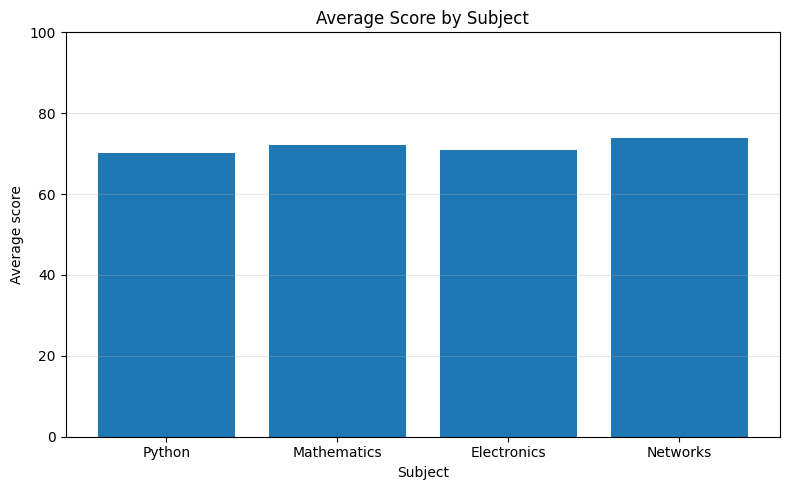

In [ ]:
# Part F — File I/O and visualization
np.save("assignment1_scores.npy", scores)
reloaded_scores = np.load("assignment1_scores.npy")
print("Saved and reloaded scores.")
print("Reloaded shape:", reloaded_scores.shape)
print("Arrays are equal:", np.array_equal(reloaded_scores, scores))

plt.figure(figsize=(8, 5))
plt.bar(subjects, subject_mean)
plt.title("Average Score by Subject")
plt.xlabel("Subject")
plt.ylabel("Average score")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Your interpretation:**

The strongest subject by average score is **Networks**, followed closely by Mathematics. Students ST03 and ST08 have the highest overall averages, showing consistently strong performance across the four modules. ST04 and ST12 need support because each has multiple scores below 50. ST09 also needs attention, particularly in Mathematics, where the score is 47. The lecturer could offer targeted revision and check each student's progress rather than relying only on the overall average.

---
# Assignment 2 — Network Performance Analysis (30 marks)
**Scenario:** Eight network monitoring intervals record throughput, latency, packet loss, and utilization. Analyze their performance and compute a simple composite score. This is an **illustrative classroom scoring rule**, not a telecom standard.

**Units:** throughput (Mbps), latency (ms), packet loss (%), utilization (%).

In [ ]:
intervals = np.arange(1, 9)
metrics = np.array([
    [85,  18, 0.2, 54], [73,  32, 0.6, 65],
    [60,  48, 1.2, 72], [45,  85, 2.5, 89],
    [92,  14, 0.1, 48], [68,  39, 0.9, 70],
    [51,  71, 2.1, 84], [79,  27, 0.4, 61]
], dtype=float)
metric_names = np.array(["Throughput", "Latency", "Packet loss", "Utilization"])

### Part A — Selection and vectorization (5 marks)
1. Extract the four metric columns into separate 1D arrays without a Python loop.
2. Create a Boolean mask for intervals where latency > 50 **or** packet loss > 1.5.
3. Display the full rows matching that mask.
4. Calculate throughput per unit of utilization (`throughput / utilization`) element-wise and identify its maximum.

In [ ]:
# Assignment 2 Part A — Selection and vectorization
throughput = metrics[:, 0]
latency = metrics[:, 1]
packet_loss = metrics[:, 2]
utilization = metrics[:, 3]

print("Throughput (Mbps):", throughput)
print("Latency (ms):", latency)
print("Packet loss (%):", packet_loss)
print("Utilization (%):", utilization)

problem_mask = (latency > 50) | (packet_loss > 1.5)
print("\nIntervals where latency > 50 ms OR packet loss > 1.5%:")
print("Interval numbers:", intervals[problem_mask])
print(metrics[problem_mask, :])

throughput_per_utilization = throughput / utilization
best_ratio_index = np.argmax(throughput_per_utilization)
print("\nThroughput / utilization:", throughput_per_utilization)
print(f"Maximum ratio: {throughput_per_utilization[best_ratio_index]:.4f} "
      f"at interval {intervals[best_ratio_index]}")

Throughput (Mbps): [85. 73. 60. 45. 92. 68. 51. 79.]
Latency (ms): [18. 32. 48. 85. 14. 39. 71. 27.]
Packet loss (%): [0.2 0.6 1.2 2.5 0.1 0.9 2.1 0.4]
Utilization (%): [54. 65. 72. 89. 48. 70. 84. 61.]

Intervals where latency > 50 ms OR packet loss > 1.5%:
Interval numbers: [4 7]
[[45.  85.   2.5 89. ]
 [51.  71.   2.1 84. ]]

Throughput / utilization: [1.57407407 1.12307692 0.83333333 0.50561798 1.91666667 0.97142857
 0.60714286 1.29508197]
Maximum ratio: 1.9167 at interval 5


### Part B — Universal functions and classification (6 marks)
1. Apply `np.sqrt()` to the throughput array and explain what element-wise computation means.
2. Use `np.maximum()` to enforce a minimum throughput reference of 60 Mbps **in a new array**, without modifying original data.
3. Use nested `np.where()` to classify each interval as:
   - **Good:** latency < 40 AND packet loss < 1
   - **Poor:** latency ≥ 70 OR packet loss ≥ 2
   - **Moderate:** all remaining intervals.
4. Print interval numbers and labels, and count each label using `np.unique(..., return_counts=True)`.

In [ ]:
# Assignment 2 Part B — Universal functions and classification
throughput_sqrt = np.sqrt(throughput)
print("Square root of each throughput value:", throughput_sqrt)
# Element-wise means the operation is applied separately to every array element.

throughput_reference = np.maximum(throughput, 60)
print("\nThroughput with a 60 Mbps minimum reference:", throughput_reference)
print("Original throughput remains unchanged:", throughput)

labels = np.where(
    (latency < 40) & (packet_loss < 1),
    "Good",
    np.where((latency >= 70) | (packet_loss >= 2), "Poor", "Moderate")
)
print("\nClassification by interval:")
for interval, label in zip(intervals, labels):
    print(f"Interval {interval}: {label}")

unique_labels, label_counts = np.unique(labels, return_counts=True)
print("\nClassification counts:")
for label, count in zip(unique_labels, label_counts):
    print(f"{label}: {count}")

Square root of each throughput value: [9.21954446 8.54400375 7.74596669 6.70820393 9.59166305 8.24621125
 7.14142843 8.88819442]

Throughput with a 60 Mbps minimum reference: [85. 73. 60. 60. 92. 68. 60. 79.]
Original throughput remains unchanged: [85. 73. 60. 45. 92. 68. 51. 79.]

Classification by interval:
Interval 1: Good
Interval 2: Good
Interval 3: Moderate
Interval 4: Poor
Interval 5: Good
Interval 6: Good
Interval 7: Poor
Interval 8: Good

Classification counts:
Good: 5
Moderate: 1
Poor: 2


### Part C — Statistics, sorting, and visualization (5 marks)
1. Calculate the mean and standard deviation of all four metrics by column.
2. Find the interval with the highest latency and the one with the lowest throughput.
3. Rank intervals by throughput, highest first.
4. Plot latency and throughput in separate clearly labeled graphs (do not put different units on an unlabeled shared axis). Explain any apparent relationship.

Mean by metric: {np.str_('Throughput'): np.float64(69.125), np.str_('Latency'): np.float64(41.75), np.str_('Packet loss'): np.float64(1.0), np.str_('Utilization'): np.float64(67.875)}
Standard deviation by metric: {np.str_('Throughput'): np.float64(15.341), np.str_('Latency'): np.float64(23.504), np.str_('Packet loss'): np.float64(0.828), np.str_('Utilization'): np.float64(13.09)}
Highest latency: interval 4 (85.0 ms)
Lowest throughput: interval 4 (45.0 Mbps)

Intervals ranked by throughput, highest first:
[(np.int64(5), np.float64(92.0)), (np.int64(1), np.float64(85.0)), (np.int64(8), np.float64(79.0)), (np.int64(2), np.float64(73.0)), (np.int64(6), np.float64(68.0)), (np.int64(3), np.float64(60.0)), (np.int64(7), np.float64(51.0)), (np.int64(4), np.float64(45.0))]


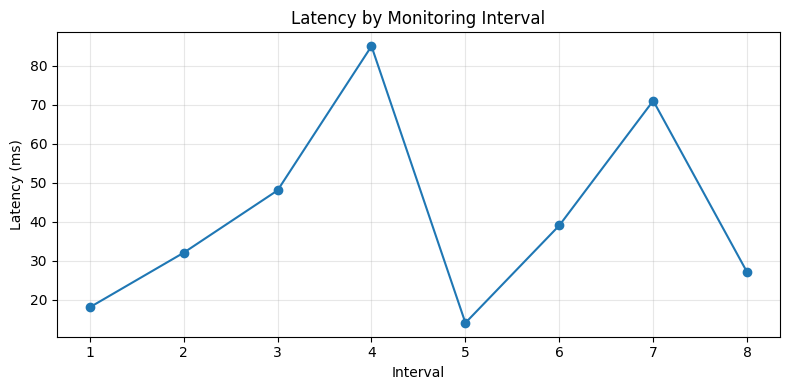

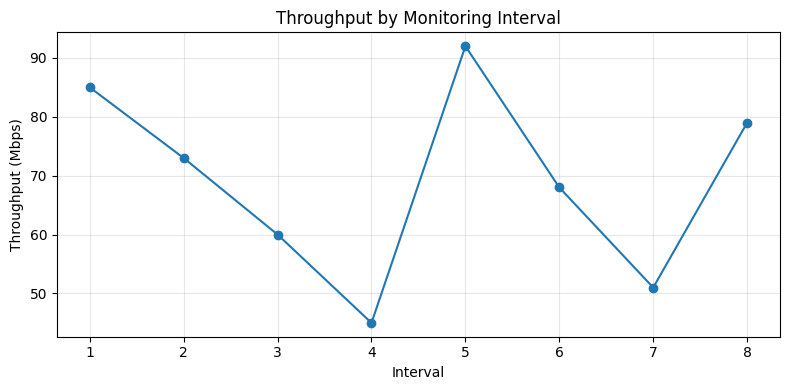

In [ ]:
# Assignment 2 Part C — Statistics, sorting, and visualization
metric_means = np.mean(metrics, axis=0)
metric_stds = np.std(metrics, axis=0)
print("Mean by metric:", dict(zip(metric_names, np.round(metric_means, 3))))
print("Standard deviation by metric:", dict(zip(metric_names, np.round(metric_stds, 3))))

highest_latency_index = np.argmax(latency)
lowest_throughput_index = np.argmin(throughput)
print(f"Highest latency: interval {intervals[highest_latency_index]} "
      f"({latency[highest_latency_index]} ms)")
print(f"Lowest throughput: interval {intervals[lowest_throughput_index]} "
      f"({throughput[lowest_throughput_index]} Mbps)")

throughput_order = np.argsort(throughput)[::-1]
print("\nIntervals ranked by throughput, highest first:")
print(list(zip(intervals[throughput_order], throughput[throughput_order])))

plt.figure(figsize=(8, 4))
plt.plot(intervals, latency, marker="o")
plt.title("Latency by Monitoring Interval")
plt.xlabel("Interval")
plt.ylabel("Latency (ms)")
plt.xticks(intervals)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(intervals, throughput, marker="o")
plt.title("Throughput by Monitoring Interval")
plt.xlabel("Interval")
plt.ylabel("Throughput (Mbps)")
plt.xticks(intervals)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# The intervals with higher latency tend to have lower throughput in this small dataset,
# but eight illustrative observations are not enough to establish causation.

### Part D — Linear algebra and composite scoring (6 marks)
Use the following **teaching-only** normalized features:

- throughput benefit = throughput / 100
- latency benefit = 1 − latency / 100
- packet-loss benefit = 1 − packet_loss / 5
- utilization benefit = 1 − utilization / 100

Weights: `[0.40, 0.30, 0.20, 0.10]` in that order.

1. Create an 8×4 benefit matrix using array operations (no row loop).
2. Calculate the weighted score for all eight intervals using matrix multiplication (`@` or `np.dot`).
3. Identify the interval with the highest weighted score.
4. Check the matrix dimensions and explain why the multiplication is valid.
5. Explain one limitation of this scoring model.

In [ ]:
# Assignment 2 Part D — Linear algebra and composite scoring
benefits = np.column_stack((
    throughput / 100,
    1 - latency / 100,
    1 - packet_loss / 5,
    1 - utilization / 100
))
weights = np.array([0.40, 0.30, 0.20, 0.10])
weighted_scores = benefits @ weights

print("Benefit matrix (8 intervals × 4 features):")
print(benefits)
print("Benefit matrix shape:", benefits.shape)
print("Weight vector shape:", weights.shape)
print("\nWeighted scores:", np.round(weighted_scores, 4))

best_score_index = np.argmax(weighted_scores)
print(f"Highest composite score: interval {intervals[best_score_index]} "
      f"({weighted_scores[best_score_index]:.4f})")

# Multiplication is valid because (8 × 4) @ (4,) produces (8,).
# Limitation: the normalization and weights are teaching choices, not validated network
# performance standards; a different choice could change the ranking.

Benefit matrix (8 intervals × 4 features):
[[0.85 0.82 0.96 0.46]
 [0.73 0.68 0.88 0.35]
 [0.6  0.52 0.76 0.28]
 [0.45 0.15 0.5  0.11]
 [0.92 0.86 0.98 0.52]
 [0.68 0.61 0.82 0.3 ]
 [0.51 0.29 0.58 0.16]
 [0.79 0.73 0.92 0.39]]
Benefit matrix shape: (8, 4)
Weight vector shape: (4,)

Weighted scores: [0.824 0.707 0.576 0.336 0.874 0.649 0.423 0.758]
Highest composite score: interval 5 (0.8740)


### Part E — Meshgrid and broadcasting (4 marks)
1. Create `latency_grid = np.arange(10, 101, 10)` and `loss_grid = np.array([0, 0.5, 1, 2, 3])`.
2. Use `np.meshgrid()` to generate every latency/loss combination.
3. Evaluate `penalty = np.sqrt((latency/100)**2 + (loss/5)**2)` across the grid using vectorization.
4. Report the shape and visualize the penalty using `plt.imshow()` with labeled axes and a colorbar.

Latency values: [ 10  20  30  40  50  60  70  80  90 100]
Packet-loss values: [0.  0.5 1.  2.  3. ]
Latency mesh shape: (5, 10)
Loss mesh shape: (5, 10)
Penalty shape: (5, 10)
Penalty grid:
[[0.1   0.2   0.3   0.4   0.5   0.6   0.7   0.8   0.9   1.   ]
 [0.141 0.224 0.316 0.412 0.51  0.608 0.707 0.806 0.906 1.005]
 [0.224 0.283 0.361 0.447 0.539 0.632 0.728 0.825 0.922 1.02 ]
 [0.412 0.447 0.5   0.566 0.64  0.721 0.806 0.894 0.985 1.077]
 [0.608 0.632 0.671 0.721 0.781 0.849 0.922 1.    1.082 1.166]]


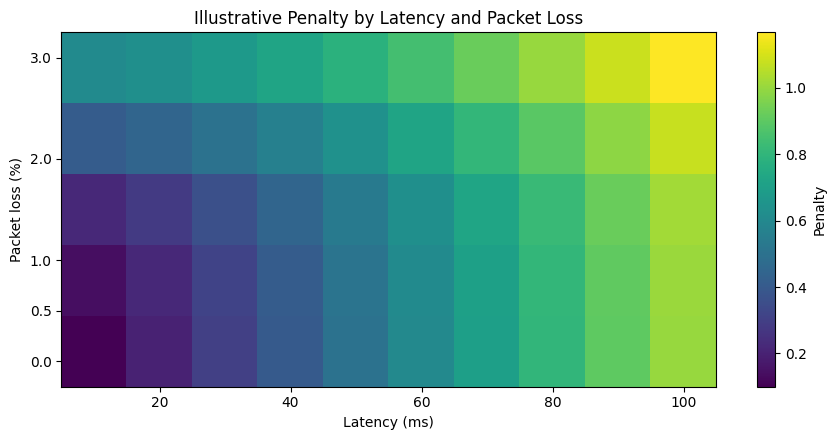

In [ ]:
# Assignment 2 Part E — Meshgrid and broadcasting
latency_grid = np.arange(10, 101, 10)
loss_grid = np.array([0, 0.5, 1, 2, 3])
latency_mesh, loss_mesh = np.meshgrid(latency_grid, loss_grid)
penalty = np.sqrt((latency_mesh / 100) ** 2 + (loss_mesh / 5) ** 2)

print("Latency values:", latency_grid)
print("Packet-loss values:", loss_grid)
print("Latency mesh shape:", latency_mesh.shape)
print("Loss mesh shape:", loss_mesh.shape)
print("Penalty shape:", penalty.shape)
print("Penalty grid:")
print(np.round(penalty, 3))

plt.figure(figsize=(9, 4.5))
image = plt.imshow(
    penalty, origin="lower", aspect="auto",
    extent=[latency_grid.min() - 5, latency_grid.max() + 5,
            loss_grid.min() - 0.25, loss_grid.max() + 0.25]
)
plt.title("Illustrative Penalty by Latency and Packet Loss")
plt.xlabel("Latency (ms)")
plt.ylabel("Packet loss (%)")
plt.yticks(loss_grid)
plt.colorbar(image, label="Penalty")
plt.tight_layout()
plt.show()

### Part F — Save, reload, and report (4 marks)
1. Save `metrics` and the weighted scores together in `assignment2_results.npz` using `np.savez()`.
2. Reload both arrays and verify their shapes.
3. Explain whether the interval with highest throughput necessarily has the highest composite score.
4. Write a short recommendation for monitoring these intervals; avoid claiming that the score itself optimizes the network.

In [ ]:
# Assignment 2 Part F — Save, reload, and report
np.savez("assignment2_results.npz", metrics=metrics, weighted_scores=weighted_scores)
with np.load("assignment2_results.npz") as saved:
    loaded_metrics = saved["metrics"]
    loaded_weighted_scores = saved["weighted_scores"]

print("Reloaded metrics shape:", loaded_metrics.shape)
print("Reloaded weighted scores shape:", loaded_weighted_scores.shape)
print("Metrics equal original:", np.array_equal(loaded_metrics, metrics))
print("Scores equal original:", np.allclose(loaded_weighted_scores, weighted_scores))

highest_throughput_index = np.argmax(throughput)
print(f"Highest-throughput interval: {intervals[highest_throughput_index]} "
      f"({throughput[highest_throughput_index]} Mbps)")
print(f"Highest-composite-score interval: {intervals[best_score_index]} "
      f"({weighted_scores[best_score_index]:.4f})")

# The highest-throughput interval does not necessarily have the highest composite score,
# because the composite score also considers latency, packet loss, and utilization.
# Recommendation: monitor all four metrics over time, investigate intervals with high
# latency or packet loss, and treat this classroom score as a rough comparison only.

Reloaded metrics shape: (8, 4)
Reloaded weighted scores shape: (8,)
Metrics equal original: True
Scores equal original: True
Highest-throughput interval: 5 (92.0 Mbps)
Highest-composite-score interval: 5 (0.8740)
